# A palaeographic date is a distribution, not a point

This notebook goes with the paper *A palaeographic date is a distribution, not a point: expert disagreement as ground truth for the dating of Greek papyri*.

It recomputes the numbers, the tables and the figures of the paper from the released data.
The sections follow the paper. Every number is printed next to the value reported in the paper, so you can check them one by one.

**Data** (folder `data/`)
- `expert_answers.csv`: the 360 answers of the study, one row per papyrus and expert.
- `vlm_answers.csv`: the answers of the four vision–language models (30 samples per papyrus, plus one greedy answer that we do not use).

**Conventions.** Years are integers and BC years are negative: −257 means 257 BC.

The whole notebook runs in a few minutes on a laptop.

In [1]:
import itertools
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr, kendalltau

# colours and style of the paper figures
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, GREY, GREY_L = "#2a78d6", "#eb6834", "#8a8984", "#cfcec9"
SINGLE, DOUBLE = 3.5, 7.2          # column widths of the journal, in inches
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.linewidth": 0.6, "figure.dpi": 130})

os.makedirs("figures", exist_ok=True)
def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")

## Section 3 — The expert study

### The data
Twenty Greek documentary papyri, one per half-century between 257 BC and AD 697. The date of each papyrus is certain because it is written in the document.
Eighteen experts saw a crop of the script (without the dated part). For each crop they gave:
- the earliest and the latest plausible year (`date_from`, `date_to`);
- their confidence, from 1 (not confident) to 5 (extremely confident);
- which extra information would help them (`requested_info`).

For each expert we also keep the periods they know best (`expert_periods`). Names and other personal details are not released.

In [2]:
ex = pd.read_csv("data/expert_answers.csv")
ex["requested_info"] = ex["requested_info"].fillna("")
ex.head()

,papyrus,tm_number,true_date,period,expert,expert_periods,date_from,date_to,confidence,requested_info
0,P01,1738,-257,Ptolemaic,E01,Byzantine,-250,-150,3,"Bigger Image (more text lines), A full transcr..."
1,P01,1738,-257,Ptolemaic,E02,Ptolemaic,-200,-100,3,"A full transcription of the document, The prov..."
2,P01,1738,-257,Ptolemaic,E03,Byzantine,-180,100,2,"Image of the full document, A full transcripti..."
3,P01,1738,-257,Ptolemaic,E04,Ptolemaic,-275,-225,5,"A full transcription of the document, The name..."
4,P01,1738,-257,Ptolemaic,E05,Roman,0,100,2,"Bigger Image (more text lines), Focus images o..."


In [3]:
papyri = ex.groupby("papyrus")[["tm_number", "true_date", "period"]].first().sort_values("true_date")
print(f"{ex.papyrus.nunique()} papyri, {ex.expert.nunique()} experts, {len(ex)} answers   (paper: 20, 18, 360)")
papyri.T

20 papyri, 18 experts, 360 answers   (paper: 20, 18, 360)


papyrus,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20
tm_number,1738,5315,2888,3646,3775,5287,12094,12270,11996,14157,12283,20331,10529,10538,18380,11523,41001,15553,41010,18867
true_date,-257,-210,-172,-119,-72,-34,33,78,124,178,224,272,325,372,429,477,531,575,622,697
period,Ptolemaic,Ptolemaic,Ptolemaic,Ptolemaic,Ptolemaic,Ptolemaic,Roman,Roman,Roman,Roman,Roman,Roman,Roman,Byzantine,Byzantine,Byzantine,Byzantine,Byzantine,Byzantine,Byzantine


We put the answers in tables with one row per papyrus (sorted by true date) and one column per expert.

In [4]:
pids = list(papyri.index)                       # papyri, sorted by true date
experts = sorted(ex.expert.unique())            # E01 ... E18
y = papyri.true_date.values.astype(float)       # true dates
per = np.array(papyri.period, dtype=str)          # true periods
nP, nE = len(pids), len(experts)

def table(col):
    return ex.pivot(index="papyrus", columns="expert", values=col).loc[pids, experts].values.astype(float)

L, U, conf = table("date_from"), table("date_to"), table("confidence")
C = (L + U) / 2       # centre of each range: the label a dataset would store
W = U - L             # width of each range
print("ranges with date_from > date_to:", int((L > U).sum()))

ranges with date_from > date_to: 0


### From answers to distributions
We read each answer as a **uniform distribution**: every year of the range has the same probability.
A range narrower than 10 years is read as a 10-year range around its centre.

The **pooled expert distribution** of a papyrus is the average of the 18 distributions.

All distributions live on a grid of years, one bin per year.

In [5]:
GRID = np.arange(-2000, 1501)   # years (wide enough for every answer, also of the models)

def uniform(lo, hi, min_width=10):
    # a range [lo, hi] as a uniform distribution on GRID (it sums to 1)
    lo, hi = min(lo, hi), max(lo, hi)
    if hi - lo < min_width:
        c = (lo + hi) / 2
        lo, hi = c - min_width / 2, c + min_width / 2
    d = ((GRID >= lo) & (GRID <= hi)).astype(float)
    return d / d.sum()

# D[p, e] = distribution of the answer of expert e on papyrus p
D = np.array([[uniform(L[p, e], U[p, e]) for e in range(nE)] for p in range(nP)])
P_all = D.mean(axis=1)           # pooled expert distribution of each papyrus
print(D.shape, P_all.shape)

(20, 18, 3501) (20, 3501)


### Measures
- **Error** of a single year: distance in years from the true date. For a range we take its centre; for a group of experts, the median of their centres.
- **CRPS** of a distribution with cumulative distribution $F$: $\int (F(t)-\mathbb{1}[t\ge y])^2\,dt$. It is in years, lower is better, and for a single year it equals the error.
- **Coverage**: how often the central 50% (or 80%) of a distribution contains the true date.
- **$W_1$**: distance between two distributions, in years.
- **95% confidence intervals**: we resample the 20 papyri 2,000 times.

In [6]:
def crps(P, y):
    # CRPS (years) of distributions P[..., grid] against true dates y[...]
    F = np.cumsum(P, axis=-1)
    H = (GRID >= np.asarray(y, float)[..., None]).astype(float)
    return ((F - H) ** 2).sum(axis=-1)

def w1(P, Q):
    # 1-Wasserstein distance (years) between distributions
    return np.abs(np.cumsum(P, -1) - np.cumsum(Q, -1)).sum(-1)

def quantile(P, q):
    # q-quantile of each distribution
    return GRID[np.argmax(np.cumsum(P, -1) >= q, axis=-1)]

def covers(P, y, level):
    # does the central `level` part of P contain the true date?
    return (quantile(P, (1 - level) / 2) <= y) & (y <= quantile(P, 1 - (1 - level) / 2))

def mass_near(P, y, tol=50):
    # probability within +-tol years of the true date
    return (P * (np.abs(GRID - np.asarray(y, float)[..., None]) <= tol)).sum(-1)

def period(x):
    return np.where(x < -30, "Ptolemaic", np.where(x < 330, "Roman", "Byzantine"))

def boot(stat, b=2000, seed=0):
    # value of stat(papyri) and 95% interval from resampling the 20 papyri
    rng = np.random.default_rng(seed)
    est = stat(np.arange(nP))
    res = [stat(rng.integers(0, nP, nP)) for _ in range(b)]
    lo, hi = np.nanpercentile(res, [2.5, 97.5])
    return est, lo, hi

def show(label, value, paper="", pct=False, d=0):
    # print our value next to the paper's value
    k, u = (100, "%") if pct else (1, "")
    if isinstance(value, tuple):
        txt = f"{value[0]*k:.{d}f}{u} [{value[1]*k:.{d}f}, {value[2]*k:.{d}f}]"
    elif isinstance(value, str):
        txt = value
    else:
        txt = f"{value*k:.{d}f}{u}"
    print(f"{label:<50} {txt:<22} paper: {paper}")

## Section 4 — What a single expert's label is worth

### Table 1: the expert study in numbers

In [7]:
err = np.abs(C - y[:, None])                       # error of each label
inside = (L <= y[:, None]) & (y[:, None] <= U)     # true date inside the range
wrong_period = period(C) != per[:, None]           # centre in the wrong historical period
P_conf = (D * conf[..., None]).sum(1) / conf.sum(1)[:, None]   # pooled, weighted by confidence

def icc21(X):
    # ICC(2,1) of a papyri x experts table
    n, k = X.shape
    g, r, c = X.mean(), X.mean(1), X.mean(0)
    msr = k * ((r - g) ** 2).sum() / (n - 1)
    msc = n * ((c - g) ** 2).sum() / (k - 1)
    mse = ((X - r[:, None] - c[None, :] + g) ** 2).sum() / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

pairs = [np.abs(C[:, i] - C[:, j]).mean() for i, j in itertools.combinations(range(nE), 2)]
icc_within = [icc21(C[per == p]) for p in ["Ptolemaic", "Roman", "Byzantine"]]

print("SINGLE EXPERT")
show("Width of the date range (years)", boot(lambda i: W[i].mean()), "134 [130, 138]")
show("True date inside the range", boot(lambda i: inside[i].mean()), "41% [34, 48]", pct=True)
show("  best / worst expert", f"{inside.mean(0).max():.0%} / {inside.mean(0).min():.0%}", "85% / 10%")
show("Error of the centre (years)", boot(lambda i: err[i].mean()), "119 [101, 138]")
show("  best / worst expert", f"{err.mean(0).min():.0f} / {err.mean(0).max():.0f}", "43 / 216")
show("Centre in the wrong historical period", boot(lambda i: wrong_period[i].mean()), "25% [15, 37]", pct=True)
show("CRPS (years)", boot(lambda i: crps(D[i], y[i][:, None]).mean()), "101 [83, 119]")
print("\nAGREEMENT")
show("Difference between two experts (years)", np.mean(pairs), "140")
show("ICC(2,1), all papyri", boot(lambda i: icc21(C[i])), "0.74 [0.60, 0.80]", d=2)
show("ICC(2,1), within a period", f"{min(icc_within):.2f}-{max(icc_within):.2f}", "0.20-0.22")
print("\nTHE 18 ANSWERS POOLED")
show("Error of the median centre (years)", boot(lambda i: np.abs(np.median(C[i], 1) - y[i]).mean()), "73 [50, 100]")
show("CRPS (years)", boot(lambda i: crps(P_all[i], y[i]).mean()), "52 [40, 65]")
show("  answers weighted by confidence", boot(lambda i: crps(P_conf[i], y[i]).mean()), "47 [37, 59]")

SINGLE EXPERT
Width of the date range (years)                    134 [130, 138]         paper: 134 [130, 138]
True date inside the range                         41% [34, 48]           paper: 41% [34, 48]
  best / worst expert                              85% / 10%              paper: 85% / 10%
Error of the centre (years)                        119 [101, 138]         paper: 119 [101, 138]
  best / worst expert                              43 / 216               paper: 43 / 216
Centre in the wrong historical period              25% [15, 37]           paper: 25% [15, 37]


CRPS (years)                                       101 [83, 119]          paper: 101 [83, 119]

AGREEMENT
Difference between two experts (years)             140                    paper: 140
ICC(2,1), all papyri                               0.74 [0.60, 0.80]      paper: 0.74 [0.60, 0.80]
ICC(2,1), within a period                          0.20-0.22              paper: 0.20-0.22

THE 18 ANSWERS POOLED
Error of the median centre (years)                 73 [50, 100]           paper: 73 [50, 100]


CRPS (years)                                       52 [40, 65]            paper: 52 [40, 65]


  answers weighted by confidence                   47 [37, 59]            paper: 47 [37, 59]


### Figure 1: three papyri
Top: the 18 ranges, sorted by centre (darker = higher confidence). Bottom: the pooled distribution. Black line: true date.
- P05: the majority is correct.
- P02: a clear majority is about two centuries too late.
- P13: the experts split almost evenly between a correct and a wrong date.

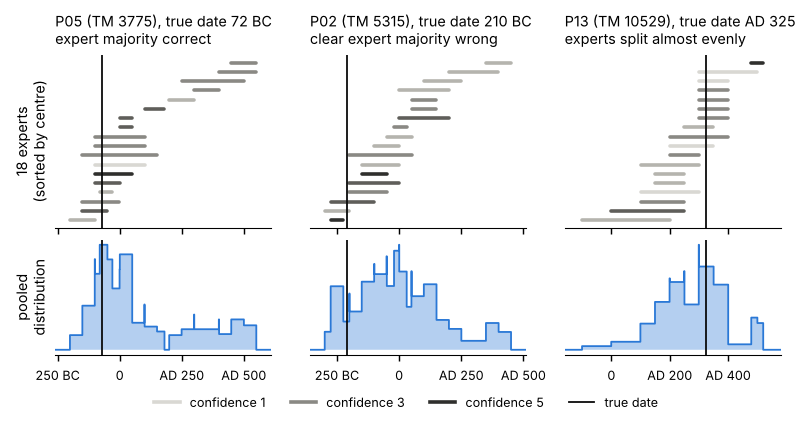

In [8]:
def year_label(v, _=None):
    v = int(round(v))
    return f"{-v} BC" if v < 0 else (f"AD {v}" if v > 0 else "0")

shades = {1: "#d9d8d3", 2: "#b5b4ae", 3: "#8a8984", 4: "#5f5e5a", 5: "#2f2f2d"}   # confidence 1..5
show_pap = [("P05", "expert majority correct"), ("P02", "clear expert majority wrong"),
            ("P13", "experts split almost evenly")]

fig, axs = plt.subplots(2, 3, figsize=(DOUBLE, 3.0), sharex="col",
                        gridspec_kw={"height_ratios": [1.5, 1], "hspace": 0.08, "wspace": 0.18})
for c, (pid, note) in enumerate(show_pap):
    p = pids.index(pid)
    order = np.argsort(C[p])
    ax = axs[0, c]
    for r, e in enumerate(order):
        ax.plot([L[p, e], U[p, e]], [r, r], color=shades[int(conf[p, e])], lw=2, solid_capstyle="round")
    ax.axvline(y[p], color=INK, lw=1)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_title(f"{pid} (TM {papyri.tm_number[pid]}), true date {year_label(y[p])}\n{note}", loc="left")
    ax = axs[1, c]
    dens = P_all[p] / P_all[p].max()
    ax.fill_between(GRID, dens, step="mid", color=BLUE, alpha=0.35, lw=0)
    ax.plot(GRID, dens, drawstyle="steps-mid", color=BLUE, lw=1)
    ax.axvline(y[p], color=INK, lw=1)
    ax.set_xlim(min(L[p].min(), y[p]) - 60, max(U[p].max(), y[p]) + 60)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.xaxis.set_major_formatter(year_label); ax.locator_params(axis="x", nbins=4)
axs[0, 0].set_ylabel("18 experts\n(sorted by centre)")
axs[1, 0].set_ylabel("pooled\ndistribution")
handles = [Line2D([], [], color=shades[k], lw=2, label=f"confidence {k}") for k in [1, 3, 5]]
handles += [Line2D([], [], color=INK, lw=1, label="true date")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
save(fig, "fig1_examples"); plt.show()

### A single label is noisy
If a dataset stores the centre of one expert's range, how far is this label from the truth?

In [9]:
show("Labels off by more than a century", boot(lambda i: (err[i] > 100).mean()), "45% [39, 52]", pct=True)
show("Labels in the wrong historical period", boot(lambda i: wrong_period[i].mean()), "25%", pct=True)
show("Two experts on the same papyrus differ by (years)", np.mean(pairs), "140")

Labels off by more than a century                  45% [39, 52]           paper: 45% [39, 52]
Labels in the wrong historical period              25% [15, 37]           paper: 25%
Two experts on the same papyrus differ by (years)  140                    paper: 140


### Experts agree on the period, not on the century
Over all papyri the agreement looks good, because the papyri span a thousand years.
Inside one period, where experts must choose the century, the agreement drops.

In [10]:
show("ICC(2,1), all papyri", icc21(C), "0.74", d=2)
for p, v in zip(["Ptolemaic", "Roman", "Byzantine"], icc_within):
    show(f"ICC(2,1), {p} papyri only ({(per == p).sum()})", v, "about 0.20", d=2)

ICC(2,1), all papyri                               0.74                   paper: 0.74
ICC(2,1), Ptolemaic papyri only (6)                0.22                   paper: about 0.20
ICC(2,1), Roman papyri only (7)                    0.20                   paper: about 0.20
ICC(2,1), Byzantine papyri only (7)                0.20                   paper: about 0.20


### Single experts are overconfident, the group is not (Figure 2)
We read each range as uniform and take its central part, e.g. its central 80% (from the 10th to the 90th percentile).
If an expert were calibrated, this central 80% would contain the true date in 80% of the answers.
We do the same for the pooled distribution of each papyrus.

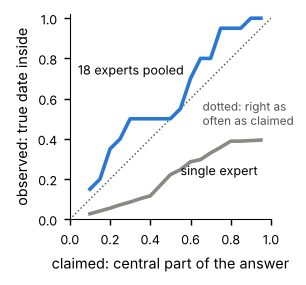

Median width of a range (years)                    100                    paper: 100


Single expert: central 80% contains the true date  39% [32, 46]           paper: 39%
Pooled: central 50% contains the true date         50%                    paper: 50%
Pooled: central 80% contains the true date         95%                    paper: 95% (19 of 20)


In [11]:
levels = np.linspace(0.1, 0.95, 18)
single_cov = [(err <= q * W / 2).mean() for q in levels]          # central q of a uniform range
pooled_cov = [covers(P_all, y, q).mean() for q in levels]

fig, ax = plt.subplots(figsize=(SINGLE, 2.05))
ax.plot([0, 1], [0, 1], color=INK2, lw=0.8, ls=":")
ax.plot(levels, pooled_cov, color=BLUE, lw=2)
ax.plot(levels, single_cov, color=GREY, lw=2)
ax.text(0.04, 0.72, "18 experts pooled", fontsize=7)
ax.text(0.55, 0.22, "single expert", fontsize=7)
ax.text(0.66, 0.47, "dotted: right as\noften as claimed", color=INK2, fontsize=6.5)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("claimed: central part of the answer"); ax.set_ylabel("observed: true date inside")
save(fig, "fig2_calibration"); plt.show()

show("Median width of a range (years)", np.median(W), "100")
show("Single expert: central 80% contains the true date", boot(lambda i: (err[i] <= 0.8 * W[i] / 2).mean()), "39%", pct=True)
show("Pooled: central 50% contains the true date", covers(P_all, y, 0.5).mean(), "50%", pct=True)
show("Pooled: central 80% contains the true date", covers(P_all, y, 0.8).mean(), "95% (19 of 20)", pct=True)

**Sensitivity check.** Two other ways to pool the answers: weighted by confidence, and reading each range as the central 80% of a normal distribution ($\sigma = (u-\ell)/2.56$). They give similar results.

In [12]:
def gauss(c, w):
    g = np.exp(-0.5 * ((GRID - c) / max(w / 2.56, 5)) ** 2)
    return g / g.sum()

P_gauss = np.array([[gauss(C[p, e], W[p, e]) for e in range(nE)] for p in range(nP)]).mean(1)
variants = {"uniform (main)": P_all, "weighted by confidence": P_conf, "normal, range = central 80%": P_gauss}
pd.DataFrame({name: {"CRPS (years)": crps(P, y).mean(),
                     "central 50% covers": covers(P, y, 0.5).mean(),
                     "central 80% covers": covers(P, y, 0.8).mean()} for name, P in variants.items()}).round(2)

,uniform (main),weighted by confidence,"normal, range = central 80%"
CRPS (years),51.57,47.47,52.02
central 50% covers,0.50,0.55,0.55
central 80% covers,0.95,0.95,0.95


### Specialists do better
The experts told us which periods they know best. For each papyrus we keep only the experts who know its period.

In [13]:
expert_periods = ex.groupby("expert").expert_periods.first().loc[experts]
spec = {p: expert_periods.str.contains(p).values for p in ["Ptolemaic", "Roman", "Byzantine"]}
S = np.stack([spec[per[p]] for p in range(nP)])        # S[p, e]: expert e knows the period of papyrus p
print("specialists per period:", {p: int(v.sum()) for p, v in spec.items()})

def pool(M):
    # pooled distribution of each papyrus using only the experts in M[p]
    return np.stack([D[p, M[p]].mean(0) for p in range(nP)])

def median_centre_error(M):
    return np.abs(np.array([np.median(C[p, M[p]]) for p in range(nP)]) - y)

P_spec = pool(S)
crps_all, crps_spec = crps(P_all, y), crps(P_spec, y)
show("All 18: error of the median centre (years)", median_centre_error(np.ones_like(S)).mean(), "73")
show("Specialists: error of the median centre (years)", median_centre_error(S).mean(), "50")
show("All 18: CRPS (years)", crps_all.mean(), "52")
show("Specialists: CRPS (years)", crps_spec.mean(), "34")

specialists per period: {'Ptolemaic': 6, 'Roman': 8, 'Byzantine': 11}
All 18: error of the median centre (years)         73                     paper: 73
Specialists: error of the median centre (years)    50                     paper: 50
All 18: CRPS (years)                               52                     paper: 52
Specialists: CRPS (years)                          34                     paper: 34


Is this only an effect of the group size? We draw random groups with the same number of experts as the specialists (2,000 draws).

In [14]:
rng = np.random.default_rng(6)
rand_crps, rand_err = [], []
for _ in range(2000):
    pick = {p: rng.choice(nE, spec[p].sum(), replace=False) for p in spec}
    M = np.zeros_like(S)
    for p in range(nP):
        M[p, pick[per[p]]] = True
    rand_crps.append(crps(pool(M), y).mean())
    rand_err.append(median_centre_error(M).mean())

show("Random groups of the same size: CRPS (years)", np.mean(rand_crps), "no better than the full panel (52)")
show("Random groups of the same size: median error", np.mean(rand_err), "")
show("Random groups as good as the specialists (CRPS)", np.mean(np.array(rand_crps) <= crps_spec.mean()), "", pct=True, d=1)

print("\nCRPS by period (most of the gain comes from the Ptolemaic papyri):")
pd.DataFrame({"period": per, "all 18": crps_all, "specialists": crps_spec}).groupby("period").mean().round(0)

Random groups of the same size: CRPS (years)       56                     paper: no better than the full panel (52)
Random groups of the same size: median error       79                     paper: 
Random groups as good as the specialists (CRPS)    0.1%                   paper: 

CRPS by period (most of the gain comes from the Ptolemaic papyri):


,all 18,specialists
period,,
Byzantine,37.0,37.0
Ptolemaic,85.0,36.0
Roman,37.0,29.0


**A limitation.** To pick the specialists we must know the period, which is part of what we want to find.
Here we first guess the period from the median of the pooled distribution of all 18 experts.

In [15]:
guess = period(quantile(P_all, 0.5))
P_routed = pool(np.stack([spec[guess[p]] for p in range(nP)]))
show("Period guessed correctly (papyri)", f"{(guess == per).sum()} of {nP}", "16")
print("   missed:", [f"{pids[p]} ({per[p]})" for p in np.where(guess != per)[0]])
show("CRPS with the guessed period (years)", crps(P_routed, y).mean(), "about half of the gain is lost")
print(f"   gain with known period: {crps_all.mean() - crps_spec.mean():.0f} y, "
      f"with guessed period: {crps_all.mean() - crps(P_routed, y).mean():.0f} y")

Period guessed correctly (papyri)                  16 of 20               paper: 16
   missed: ['P02 (Ptolemaic)', 'P04 (Ptolemaic)', 'P05 (Ptolemaic)', 'P06 (Ptolemaic)']
CRPS with the guessed period (years)               42                     paper: about half of the gain is lost
   gain with known period: 18 y, with guessed period: 9 y


**Oldest and latest papyri are not easier.** The experts pull their answers towards the middle of the millennium: the error (answer − true date) goes down as the true date goes up.

In [16]:
signed = quantile(P_all, 0.5) - y
r = spearmanr(y, signed)
show("Spearman(true date, signed error of the pooled median)", f"{r.statistic:.2f} (p = {r.pvalue:.3f})", "negative = pull to the centre")

Spearman(true date, signed error of the pooled median) -0.76 (p = 0.000)      paper: negative = pull to the centre


## Section 5 — Consequences for evaluation

### The systems
We rank 26 systems:
- the 18 experts (their centres and their ranges);
- the four VLMs of Section 6 (point = median centre of the 30 answers, distribution = their pooled answers);
- three image-blind baselines: always AD 100–200; always 300 BC–AD 700; the "typical expert answer" (all 360 expert answers pooled, the same for every papyrus);
- an oracle that gives the true date.

In [17]:
vlm = pd.read_csv("data/vlm_answers.csv")
vlm = vlm[vlm["sample"] != "greedy"].copy()                    # we use the 30 sampled answers
vlm["lo"] = vlm[["date_from", "date_to"]].min(axis=1)
vlm["hi"] = vlm[["date_from", "date_to"]].max(axis=1)
MODEL_NAMES = {"qwen3-vl-32b": "Qwen3-VL-32B", "qwen3-vl-8b": "Qwen3-VL-8B",
               "gemma-3-27b": "Gemma-3-27B", "internvl-8b": "InternVL3.5-8B"}
print(vlm.groupby("model").size().rename("answers"))

def answers_of(model, pid):
    g = vlm[(vlm.model == model) & (vlm.papyrus == pid)]
    return g.lo.values, g.hi.values

point, dist = {}, {}                                            # name -> 20 dates, 20 distributions
for e, name in enumerate(experts):
    point[name], dist[name] = C[:, e], D[:, e]
for m, nice in MODEL_NAMES.items():
    pts, dens = [], []
    for pid in pids:
        lo, hi = answers_of(m, pid)
        pts.append(np.median((lo + hi) / 2))
        dens.append(np.mean([uniform(a, b) for a, b in zip(lo, hi)], axis=0))
    point[nice], dist[nice] = np.array(pts), np.array(dens)
P_typical = D.reshape(-1, len(GRID)).mean(0)                   # all 360 answers pooled
baselines = {"always AD 100–200": (150.0, uniform(100, 200)),
             "always 300 BC–AD 700": (200.0, uniform(-300, 700)),
             "typical expert answer": (np.median(C), P_typical)}
for name, (pt, den) in baselines.items():
    point[name], dist[name] = np.full(nP, pt), np.tile(den, (nP, 1))
point["oracle (true date)"] = y.copy()
dist["oracle (true date)"] = np.stack([uniform(v - 5, v + 5) for v in y])
names = list(point)
print(len(names), "systems")

model
gemma-3-27b     600
internvl-8b     600
qwen3-vl-32b    600
qwen3-vl-8b     600
Name: answers, dtype: int64
26 systems


### Scores under different ground truths
Each system is scored by the mean absolute error of its point prediction against:
- the true date;
- the labels of one expert (18 alternatives);
- the median of the expert labels;
- and, for the distributional ground truth, the $W_1$ distance between the system's distribution and the pooled expert distribution.

An expert is never part of the ground truth used to score that expert. For the other systems, the two group ground truths are averaged over the 18 panels that leave one expert out, so that every system is scored against 17 experts.

In [18]:
def group_score(s, kind):
    if s in experts:
        panels = [[e for e in range(nE) if experts[e] != s]]
    else:
        panels = [[e for e in range(nE) if e != drop] for drop in range(nE)]
    if kind == "median":
        return np.mean([np.abs(point[s] - np.median(C[:, A], 1)).mean() for A in panels])
    return np.mean([w1(dist[s], D[:, A].mean(1)).mean() for A in panels])

scores = {"true date": {s: np.abs(point[s] - y).mean() for s in names}}
for j, ej in enumerate(experts):
    scores[f"labels of {ej}"] = {s: np.abs(point[s] - C[:, j]).mean() if s != ej else np.nan for s in names}
scores["median of experts"] = {s: group_score(s, "median") for s in names}
scores["expert distribution (W1)"] = {s: group_score(s, "dist") for s in names}
scores = pd.DataFrame(scores)
ranks = scores.rank(method="average")          # 1 = best
single_gt = [c for c in scores if c.startswith("labels of")]

### Rankings depend on who annotated (Figure 3)
Dot: rank against the true date. Bar: range of ranks when the ground truth is the labels of one of the 18 experts.

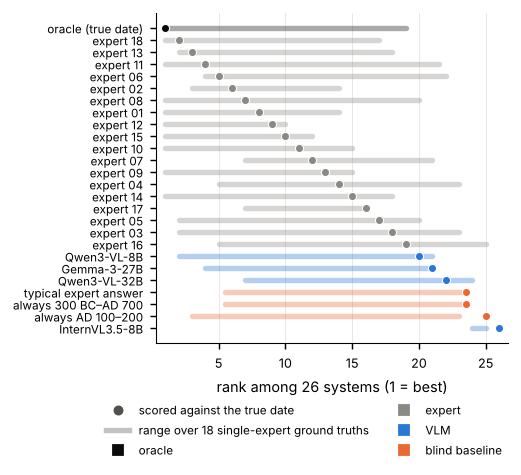

oracle (true date): rank under one expert's labels 1 to 19                paper: 1st to 19th
Qwen3-VL-8B: rank under one expert's labels        2 to 21                paper: 2nd to 21st
always AD 100–200: rank under one expert's labels  3 to 23                paper: 3rd to 23rd
Oracle error against one expert's labels (years)   43 to 216              paper: 43 to 216


In [19]:
rr = pd.DataFrame({"truth": ranks["true date"], "min": ranks[single_gt].min(axis=1),
                   "max": ranks[single_gt].max(axis=1)}).sort_values("truth")

def kind(s):
    if s.startswith("oracle"): return "oracle"
    if s in experts: return "expert"
    if s in baselines: return "blind baseline"
    return "VLM"
colour = {"oracle": INK, "expert": GREY, "VLM": BLUE, "blind baseline": ORANGE}

fig, ax = plt.subplots(figsize=(SINGLE, 3.3))
for i, (s, r) in enumerate(rr.iterrows()):
    ax.plot([r["min"], r["max"]], [i, i], color=colour[kind(s)], lw=3, alpha=0.35, solid_capstyle="round")
    ax.plot(r["truth"], i, "o", color=colour[kind(s)], ms=4.5, mec="white", mew=0.6)
ax.set_yticks(range(len(rr)))
ax.set_yticklabels([s.replace("E", "expert ") if s in experts else s for s in rr.index], fontsize=6.5)
ax.invert_yaxis()
ax.set_xlabel(f"rank among {len(names)} systems (1 = best)"); ax.set_xlim(0.3, len(names) + 0.7)
ax.xaxis.grid(True, color=GRID_C, lw=0.5); ax.set_axisbelow(True)
handles = [Line2D([], [], marker="o", color=INK2, ls="", ms=4.5, label="scored against the true date"),
           Line2D([], [], color=INK2, lw=3, alpha=0.35, label="range over 18 single-expert ground truths")]
handles += [Line2D([], [], marker="s", color=colour[k], ls="", ms=5, label=k) for k in colour]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.42, -0.15), ncol=2, frameon=False, fontsize=6.5)
save(fig, "fig3_rank_instability"); plt.show()

for s, paper in [("oracle (true date)", "1st to 19th"), ("Qwen3-VL-8B", "2nd to 21st"), ("always AD 100–200", "3rd to 23rd")]:
    show(f"{s}: rank under one expert's labels", f"{rr.loc[s, 'min']:.0f} to {rr.loc[s, 'max']:.0f}", paper)
oracle_mae = scores.loc["oracle (true date)", single_gt]
show("Oracle error against one expert's labels (years)", f"{oracle_mae.min():.0f} to {oracle_mae.max():.0f}", "43 to 216")

We compare rankings with Kendall's $\tau$ (1 = same order, 0 = unrelated).

In [20]:
def tau(a, b):
    ok = ranks[a].notna() & ranks[b].notna()
    return kendalltau(ranks.loc[ok, a], ranks.loc[ok, b])[0]

taus = np.array([tau("true date", c) for c in single_gt])
show("tau: true date vs one expert's labels, median", np.median(taus), "0.60", d=2)
show("  min / max over the 18 experts", f"{taus.min():.2f} / {taus.max():.2f}", "-0.23 / 0.95")
show("tau: true date vs median of experts", tau("true date", "median of experts"), "", d=2)
show("tau: true date vs expert distribution (W1)", tau("true date", "expert distribution (W1)"), "", d=2)

tau: true date vs one expert's labels, median      0.60                   paper: 0.60
  min / max over the 18 experts                    -0.23 / 0.95           paper: -0.23 / 0.95
tau: true date vs median of experts                0.72                   paper: 
tau: true date vs expert distribution (W1)         0.70                   paper: 


### More experts give a stable evaluation
In practice the true date is unknown. So we ask: do two **different** groups of experts give the same ranking?
We split the experts into two separate groups of $k$, use each group as ground truth, and rank the eight non-expert systems (VLMs, baselines, oracle) under each. 500 random splits per $k$.

In [21]:
others = [s for s in names if s not in experts]
Pt = np.stack([point[s] for s in others]); Pd = np.stack([dist[s] for s in others])
rng = np.random.default_rng(4)
rows = []
for k in [1, 3, 5, 9]:
    for _ in range(500):
        perm = rng.permutation(nE)
        A, B = perm[:k], perm[k:2 * k]
        for gt in ["median label", "distribution (W1)"]:
            if gt == "median label":
                sa = np.abs(Pt - np.median(C[:, A], 1)).mean(1)
                sb = np.abs(Pt - np.median(C[:, B], 1)).mean(1)
            else:
                sa = w1(Pd, D[:, A].mean(1)[None]).mean(1)
                sb = w1(Pd, D[:, B].mean(1)[None]).mean(1)
            rows.append({"k": k, "ground truth": gt, "tau": kendalltau(sa, sb)[0]})
rep = pd.DataFrame(rows).groupby(["ground truth", "k"]).tau.agg(
    mean="mean", p5=lambda v: np.percentile(v, 5)).round(2)

show("k = 1: mean tau between the two rankings", rep.loc[("median label", 1), "mean"], "0.69", d=2)
show("k = 1: 5th percentile of tau", rep.loc[("median label", 1), "p5"], "below 0.19 in 5% of splits", d=2)
show("k = 9, median label: mean tau", rep.loc[("median label", 9), "mean"], "0.83", d=2)
show("k = 9, pooled distribution: mean tau", rep.loc[("distribution (W1)", 9), "mean"], "0.88", d=2)
rep.unstack(0)

k = 1: mean tau between the two rankings           0.69                   paper: 0.69
k = 1: 5th percentile of tau                       0.19                   paper: below 0.19 in 5% of splits
k = 9, median label: mean tau                      0.83                   paper: 0.83
k = 9, pooled distribution: mean tau               0.88                   paper: 0.88


mean                             p5             
ground truth distribution (W1) median label distribution (W1) median label
k                                                                         
1                         0.76         0.69              0.43         0.19
3                         0.75         0.78              0.43         0.48
5                         0.80         0.81              0.50         0.48
9                         0.88         0.83              0.71         0.63

### How many experts (Figure 4)
Random panels of $k$ experts (500 draws per $k$, the same panel for all papyri).
(a) CRPS of the panel's distribution and error of its median label, against the true date.
(b) Difference between two separate panels of $k$ experts.

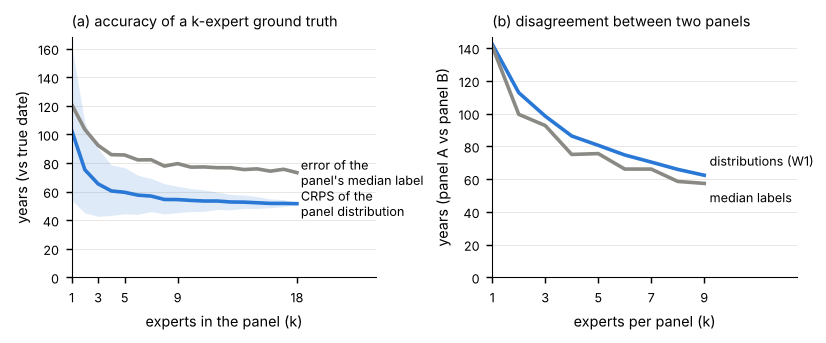

CRPS of a panel of 1                               103                    paper: 103
CRPS of a panel of 3                               65                     paper: 65
CRPS of a panel of 5                               60                     paper: 60
CRPS of a panel of 18                              52                     paper: 52


In [22]:
rng = np.random.default_rng(1)
rows = []
for k in range(1, nE + 1):
    crps_k, err_k, w_k, med_k = [], [], [], []
    for _ in range(1 if k == nE else 500):
        perm = rng.permutation(nE)
        A = perm[:k]
        P = D[:, A].mean(1)
        crps_k.append(crps(P, y).mean())
        err_k.append(np.abs(np.median(C[:, A], 1) - y).mean())
        if 2 * k <= nE:                                   # a second, separate panel
            B = perm[k:2 * k]
            w_k.append(w1(P, D[:, B].mean(1)).mean())
            med_k.append(np.abs(np.median(C[:, A], 1) - np.median(C[:, B], 1)).mean())
    rows.append({"k": k, "crps": np.mean(crps_k), "crps_p10": np.percentile(crps_k, 10),
                 "crps_p90": np.percentile(crps_k, 90), "median_label_error": np.mean(err_k),
                 "w1_two_panels": np.mean(w_k) if w_k else np.nan,
                 "median_diff_two_panels": np.mean(med_k) if med_k else np.nan})
T = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 2, figsize=(DOUBLE, 2.4), gridspec_kw={"wspace": 0.38})
ax = axs[0]
ax.fill_between(T.k, T.crps_p10, T.crps_p90, color=BLUE, alpha=0.15, lw=0)
ax.plot(T.k, T.crps, color=BLUE, lw=2); ax.plot(T.k, T.median_label_error, color=GREY, lw=2)
ax.text(18.3, T.crps.iloc[-1], "CRPS of the\npanel distribution", va="center", fontsize=7)
ax.text(18.3, T.median_label_error.iloc[-1], "error of the\npanel's median label", va="center", fontsize=7)
ax.set_xlim(1, 24); ax.set_xticks([1, 3, 5, 9, 18]); ax.set_ylim(0, None)
ax.set_xlabel("experts in the panel (k)"); ax.set_ylabel("years (vs true date)")
ax.set_title("(a) accuracy of a k-expert ground truth", loc="left")
ax.yaxis.grid(True, color=GRID_C, lw=0.5); ax.set_axisbelow(True)
ax = axs[1]; m = T.w1_two_panels.notna()
ax.plot(T.k[m], T.w1_two_panels[m], color=BLUE, lw=2)
ax.plot(T.k[m], T.median_diff_two_panels[m], color=GREY, lw=2)
ax.text(9.2, T.w1_two_panels[m].iloc[-1] + 4, "distributions (W1)", fontsize=7, va="bottom")
ax.text(9.2, T.median_diff_two_panels[m].iloc[-1] - 4, "median labels", fontsize=7, va="top")
ax.set_xlim(1, 12.5); ax.set_xticks([1, 3, 5, 7, 9]); ax.set_ylim(0, None)
ax.set_xlabel("experts per panel (k)"); ax.set_ylabel("years (panel A vs panel B)")
ax.set_title("(b) disagreement between two panels", loc="left")
ax.yaxis.grid(True, color=GRID_C, lw=0.5); ax.set_axisbelow(True)
save(fig, "fig4_panel_size"); plt.show()

for k, paper in [(1, "103"), (3, "65"), (5, "60"), (18, "52")]:
    show(f"CRPS of a panel of {k}", T.set_index("k").crps[k], paper)

## Section 6 — Case study: vision–language models

Four open-weight VLMs got the experts' task on the same crops: Qwen3-VL-8B and 32B, InternVL3.5-8B, Gemma-3-27B.
Each model gave 30 answers per papyrus (range, confidence, rationale). The 30 answers form the model's distribution.

### Table 2: VLMs, experts, blind baselines
- **Error**: mean error of a single answer (its centre).
- **CRPS** and **Prob.**: of the pooled distribution. Prob. is the probability within 50 years of the true date.
- **Slope**: regression of the median answer on the true date (1 = exact date, 0 = always the same answer).

In [23]:
def table2_row(answers):
    # answers[p] = (lo, hi) arrays of all answers of a source on papyrus p
    err, crps_, prob, med = [], [], [], []
    for p, (lo, hi) in enumerate(answers):
        mid = (lo + hi) / 2
        P = np.mean([uniform(a, b) for a, b in zip(lo, hi)], axis=0)
        err.append(np.abs(mid - y[p]).mean())
        crps_.append(crps(P, y[p]))
        prob.append(mass_near(P, y[p]))
        med.append(np.median(mid))
    return {"Error": np.mean(err), "CRPS": np.mean(crps_), "Prob.": np.mean(prob),
            "Slope": np.polyfit(y, med, 1)[0]}

src = {"Experts": [(L[p], U[p]) for p in range(nP)]}
for m in ["qwen3-vl-32b", "qwen3-vl-8b", "gemma-3-27b", "internvl-8b"]:
    src[MODEL_NAMES[m]] = [answers_of(m, pid) for pid in pids]
src["Always AD 100–200"] = [(np.array([100]), np.array([200]))] * nP
src["Always 300 BC–AD 700"] = [(np.array([-300]), np.array([700]))] * nP
src["Typical expert answer"] = [(L.ravel(), U.ravel())] * nP

tab2 = pd.DataFrame({s: table2_row(a) for s, a in src.items()}).T
tab2 = tab2.round({"Error": 0, "CRPS": 0, "Prob.": 2, "Slope": 2}) + 0.0     # + 0.0 turns -0.00 into 0.00
tab2[["Error", "CRPS"]] = tab2[["Error", "CRPS"]].astype(int)
paper_tab2 = pd.DataFrame([[119, 52, .32, .77], [239, 188, .12, .11], [233, 197, .12, .09], [246, 231, .10, .01],
                           [405, 258, .09, -.15], [252, 235, .10, 0], [249, 166, .10, 0], [311, 169, .10, 0]],
                          index=tab2.index, columns=tab2.columns)
pd.concat({"this notebook": tab2, "paper": paper_tab2}, axis=1)

this notebook                  paper                 
                              Error CRPS Prob. Slope Error CRPS Prob. Slope
Experts                         119   52  0.32  0.77   119   52  0.32  0.77
Qwen3-VL-32B                    239  188  0.12  0.11   239  188  0.12  0.11
Qwen3-VL-8B                     233  197  0.12  0.09   233  197  0.12  0.09
Gemma-3-27B                     246  231  0.10  0.01   246  231  0.10  0.01
InternVL3.5-8B                  405  258  0.09 -0.15   405  258  0.09 -0.15
Always AD 100–200               252  235  0.10  0.00   252  235  0.10  0.00
Always 300 BC–AD 700            249  166  0.10  0.00   249  166  0.10  0.00
Typical expert answer           311  169  0.10  0.00   311  169  0.10  0.00

### Do the answers follow the true date?
The spread of the median answers across papyri shows if a model gives the same date to every papyrus.

In [24]:
rows = {}
for s in ["Experts", "Qwen3-VL-32B", "Qwen3-VL-8B", "Gemma-3-27B", "InternVL3.5-8B"]:
    med = np.array([np.median((lo + hi) / 2) for lo, hi in src[s]])
    rows[s] = {"SD of median answers (years)": med.std(ddof=1),
               "Spearman with true date": spearmanr(med, y)[0],
               "Slope": np.polyfit(y, med, 1)[0]}
show("SD of the true dates (years)", y.std(ddof=1), "295")
show("SD of Gemma's median answers (years)", rows["Gemma-3-27B"]["SD of median answers (years)"], "11")
print("paper: Spearman 0.56-0.65 for Qwen and Gemma (Gemma: 0.555); InternVL slope -0.15")
pd.DataFrame(rows).T.round(3)

SD of the true dates (years)                       295                    paper: 295
SD of Gemma's median answers (years)               11                     paper: 11
paper: Spearman 0.56-0.65 for Qwen and Gemma (Gemma: 0.555); InternVL slope -0.15


,SD of median answers (years),Spearman with true date,Slope
Experts,234.551,0.973,0.769
Qwen3-VL-32B,57.035,0.598,0.108
Qwen3-VL-8B,41.651,0.647,0.086
Gemma-3-27B,11.419,0.555,0.013
InternVL3.5-8B,105.592,-0.380,-0.148


### Is the models' confidence useful?
Spearman correlation between confidence and error, over all answers. Negative = higher confidence goes with smaller errors (good). Positive = the opposite.

In [25]:
def conf_err(lo, hi, c, true):
    return spearmanr(c, np.abs((lo + hi) / 2 - true))[0]

out = {"Experts": conf_err(L.ravel(), U.ravel(), conf.ravel(), np.repeat(y, nE))}
ymap = dict(zip(pids, y))
for m, nice in MODEL_NAMES.items():
    g = vlm[vlm.model == m]
    out[nice] = conf_err(g.lo.values, g.hi.values, g.confidence.values, g.papyrus.map(ymap).values)
print("paper: in three models, higher confidence goes with larger errors")
pd.Series(out, name="Spearman(confidence, error)").round(2)

paper: in three models, higher confidence goes with larger errors


Experts          -0.26
Qwen3-VL-32B      0.24
Qwen3-VL-8B       0.23
Gemma-3-27B      -0.03
InternVL3.5-8B    0.29
Name: Spearman(confidence, error), dtype: float64

### Figure 5 (supplementary): answers against the true date
Small dots: single answers. Black dots: median per papyrus. Dotted line: the true date.

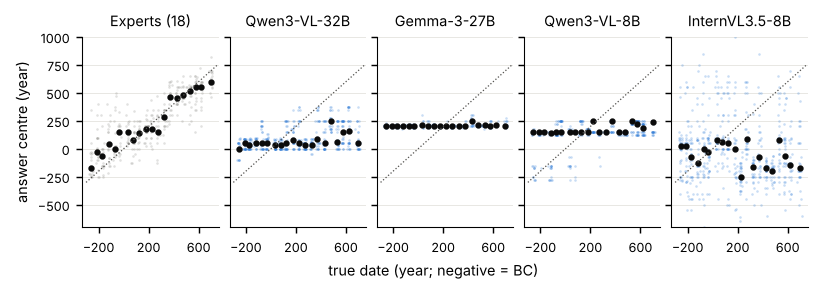

In [26]:
panels = [("Experts (18)", "Experts", GREY), ("Qwen3-VL-32B", "Qwen3-VL-32B", BLUE), ("Gemma-3-27B", "Gemma-3-27B", BLUE),
          ("Qwen3-VL-8B", "Qwen3-VL-8B", BLUE), ("InternVL3.5-8B", "InternVL3.5-8B", BLUE)]
fig, axs = plt.subplots(1, 5, figsize=(DOUBLE, 1.9), sharey=True, gridspec_kw={"wspace": 0.08})
rng = np.random.default_rng(0)
for ax, (title, s, col) in zip(axs, panels):
    xs = np.concatenate([np.full(len(lo), y[p]) for p, (lo, hi) in enumerate(src[s])])
    mids = np.concatenate([(lo + hi) / 2 for lo, hi in src[s]])
    med = [np.median((lo + hi) / 2) for lo, hi in src[s]]
    ax.scatter(xs + rng.normal(0, 7, len(xs)), mids, s=2, color=col, alpha=0.25, lw=0)
    ax.plot(y, med, "o", color=INK, ms=2.5)
    ax.plot([-300, 750], [-300, 750], color=INK2, lw=0.7, ls=":")
    ax.set_title(title); ax.set_xlim(-330, 760); ax.set_ylim(-700, 1000); ax.set_xticks([-200, 200, 600])
    ax.yaxis.grid(True, color=GRID_C, lw=0.5); ax.set_axisbelow(True)
axs[0].set_ylabel("answer centre (year)")
fig.supxlabel("true date (year; negative = BC)", fontsize=8, y=-0.1)
save(fig, "fig5_vlm_vs_experts"); plt.show()

The identification prompt (to check whether the models memorised the papyri) is not part of the released data. In the paper, all claimed editions and Trismegistos numbers were invented.

## Section 7 — Discussion: why do experts disagree?

The experts saw only the script. For each answer they could ask for more information. We count the requests over the 360 answers.

In [27]:
options = {"A full transcription of the document": "transcription",
           "Image of the full document": "full image",
           "Bigger Image (more text lines)": "larger image",
           "The provenance or findspot": "provenance",
           "The name of the collection where the papyrus is stored": "collection",
           "Focus images on individual characters or specific portions of text": "close-ups of letters"}
counts = pd.Series({short: ex.requested_info.str.contains(text, regex=False).sum() for text, short in options.items()},
                   name="answers").sort_values(ascending=False)
print("paper: transcription 244, full image 184, larger image 116, provenance 110")
print(f"answers with no request: {(ex.requested_info == '').sum()}; "
      f"experts who asked at least once: {ex[ex.requested_info != ''].expert.nunique()} of {nE}")
counts.to_frame()

paper: transcription 244, full image 184, larger image 116, provenance 110
answers with no request: 36; experts who asked at least once: 18 of 18


,answers
transcription,244
full image,184
larger image,116
provenance,110
collection,54
close-ups of letters,40


The most wanted information is the **content** of the document, not more script.

---
**Main message of the paper.** A single expert's date is a noisy and overconfident label. The pooled answers of several experts form a calibrated distribution, and they make evaluation reproducible. A palaeographic date should be collected, released and used as the distribution of several experts' answers, not as a single date.